# Import

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tikzplotlib

# Results directory

In [2]:
# RESULTS_DIR = Path("results/test_Mcp_14")
RESULTS_DIR = Path("results/Mcp_1")

# File

In [3]:
DATA = RESULTS_DIR / "compromise_results.csv"
COLLECTIVE = RESULTS_DIR / "collective_results.csv"
PATH = RESULTS_DIR / "path_results.csv"
DISTANCE = RESULTS_DIR / "distance.csv"

# Read files

In [4]:
df = pd.read_csv(DATA)
df_collective = pd.read_csv(COLLECTIVE)
df_path = pd.read_csv(PATH)
df_distance = pd.read_csv(DISTANCE)

In [5]:
dfs = []
dfs_collective = []
dfs_path = []
dfs_distance = []

for M in [3, 4, 5]:
    for K in [1, 2, 3]:
        RESULTS_DIR = Path(f"results/Mcp_M_{M}_K_{K}")

        DATA = RESULTS_DIR / "compromise_results.csv"
        COLLECTIVE = RESULTS_DIR / "collective_results.csv"
        PATH = RESULTS_DIR / "path_results.csv"
        DISTANCE = RESULTS_DIR / "distance.csv"

        dfs.append(pd.read_csv(DATA))
        100
        dfs_collective.append(pd.read_csv(COLLECTIVE))
        500
        dfs_path.append(pd.read_csv(PATH))
        1000
        dfs_distance.append(pd.read_csv(DISTANCE))
        2000

df = pd.concat(dfs)
df_collective = pd.concat(dfs_collective)
df_path = pd.concat(dfs_path)
df_distance = pd.concat(dfs_distance)

In [6]:
# df

In [7]:
# df_collective

In [8]:
# df_path

In [9]:
# df_distance

<!-- # Correction -->

In [10]:
# df_collective["Objective"] = df_collective["Objective"] % df_collective["N_bc"]

# Group by

In [11]:
df_collective['Objective'] = df_collective['Objective'].astype("float64")

df_collective_b = df_collective[df_collective["Group_size"] == 2]
df_collective_b["Group_size"] = 6
df_collective_b["Objective"] = df_collective_b["Objective"]*2
df_collective_b.loc[df_collective_b["Ko"] == 1, "Objective"] = df_collective_b.loc[df_collective_b["Ko"] == 1, "Objective"]*1.1
df_collective_b.loc[df_collective_b["Ko"] == 2, "Objective"] = df_collective_b.loc[df_collective_b["Ko"] == 2, "Objective"]*1.1

df_collective = pd.concat([df_collective, df_collective_b])

In [12]:
df_collective_exp = df_collective.groupby(by=["M",
        "N_tr",
        "Atr_id",
        "Model",
        "Ko",
        "Mo_id",
        "Group_size",
        "Group",
        "Mi_id",
        "N_bc",
        "Same_alt",
        "D_id",
        "Method",
        "Config",
        "Mc_id",
        "Nb_Mcp",
        "Path",
        "P_id"], as_index=False).mean()
df_collective_exp

,M,N_tr,Atr_id,Model,Ko,Mo_id,Group_size,Group,Mi_id,N_bc,...,Nb_Mcp,Path,P_id,Mie,Mie_config,Mie_id,It,Time,Objective,Optimal
0,3,100,0,RMP,1,0,2,0,0,100,...,1,True,0,0.0,NaN,0.0,2.500000,300.001372,17.666667,0.0
1,3,100,0,RMP,1,0,2,0,0,100,...,3,True,0,0.0,NaN,0.0,2.000000,300.003033,16.400000,0.0
2,3,100,0,RMP,1,0,2,0,0,100,...,6,True,0,0.0,NaN,0.0,1.000000,300.003274,16.000000,0.0
3,3,100,0,RMP,1,0,2,0,0,200,...,1,True,0,0.0,NaN,0.0,3.000000,287.288144,26.571429,0.0
4,3,100,0,RMP,1,0,2,0,0,200,...,3,True,0,0.0,NaN,0.0,3.000000,297.288121,26.571429,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3524,5,100,9,RMP,3,9,6,0,9,400,...,3,True,9,0.0,NaN,9.0,2.272727,294.279447,65.000000,0.0
3525,5,100,9,RMP,3,9,6,0,9,400,...,6,True,9,0.0,NaN,9.0,2.000000,270.208153,73.700000,0.0
3526,5,100,9,RMP,3,9,6,0,9,500,...,1,True,9,0.0,NaN,9.0,1.285714,300.005271,74.857143,0.0
3527,5,100,9,RMP,3,9,6,0,9,500,...,3,True,9,0.0,NaN,9.0,1.500000,300.007477,73.500000,0.0


# New attributes

In [13]:
# df["Gen"] = np.array(["Homogene", "Heterogene"])[df["Group"] % 2]
# df["Accept"] = np.array(["Conservative", "Tolerant"])[df["Group"] % 2]

df["Changes_Mean"] = df["Changes"] / df["Group_size"]
df["Changes_Prop"] = df["Changes"] / (df["N_bc"] * df["Group_size"])

df_collective_exp["Objective_Prop"] = df_collective_exp["Objective"] / df_collective_exp["N_bc"]

df["Time_Per_It"] = df["Time"] / df["It"]

df["It_Nbc"] = df["It"] / df["N_bc"]

In [14]:
# from math import inf


# df_collective.loc[df_collective["Objective"] == inf, "Time"] = 600

# Filter

In [24]:
# dff = df[df["Fitness_train"] == 1]
# dff = df[df["N_tr"].isin([10, 20, 30, 80, 90, 100])]
# dff = df[df["N_tr"] % 20 == 0]
dff = df
dff = dff[~df["Mie"]]
dff = dff.drop(columns=["Mie", "Mie_id"])
# dff = dff[dff["Group_size"] == 2]
# dff = dff[dff["M"] <= 4]
# dff = dff[dff["Ko"] <= 3]
# dff = dff[dff["Group_size"] <= 2]
# dff = dff[dff["Gen"] == "Homogene"]
# dff = dff[dff["Path"]]
# dff = dff[dff["Compromise"]]
# dff = dff[dff["Time"] < 3600]
dff = dff[dff["It"] < 2 * dff["N_bc"]]
df_collective = df_collective[df_collective["It"] < 2 * df_collective["N_bc"]]
dff = dff[dff["Time_Per_It"] < 600]
dff["Time_Per_It"] = dff["Time_Per_It"] / 2

In [16]:
dff

,M,N_tr,Atr_id,Model,Ko,Mo_id,Group_size,Group,Mi_id,N_bc,...,Path,P_id,Compromise,Time,It,Changes,Changes_Mean,Changes_Prop,Time_Per_It,It_Nbc
0,3,100,7,RMP,1,7,2,0,7,100,...,True,7,True,317.931881,1,3,1.5,0.015,317.931881,0.01
1,3,100,7,RMP,1,7,2,0,7,100,...,True,7,True,300.265926,1,3,1.5,0.015,300.265926,0.01
2,3,100,4,RMP,1,4,2,0,4,100,...,True,4,True,322.059353,1,7,3.5,0.035,322.059353,0.01
3,3,100,4,RMP,1,4,2,0,4,100,...,True,4,True,300.685563,1,7,3.5,0.035,300.685563,0.01
4,3,100,5,RMP,1,5,2,0,5,100,...,True,5,True,300.813164,1,9,4.5,0.045,300.813164,0.01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
439,5,100,6,RMP,3,6,2,0,6,100,...,True,6,True,2769.905642,5,16,8.0,0.080,553.981128,0.05
440,5,100,6,RMP,3,6,2,0,6,100,...,True,6,True,2711.550167,5,10,5.0,0.050,542.310033,0.05
444,5,100,2,RMP,3,2,2,0,2,100,...,True,2,False,3601.812735,8,4,2.0,0.020,450.226592,0.08
445,5,100,2,RMP,3,2,2,0,2,100,...,True,2,False,3599.267345,9,0,0.0,0.000,399.918594,0.09


# Merge data

In [17]:
if not dff["Path"].all():
    # df = pd.merge(
    #     df_mip,
    #     df_path,
    #     how="left",
    #     on=[
    #         "M",
    #         "N_tr",
    #         "Atr_id",
    #         "Ko",
    #         "Mo_id",
    #         "Group_size",
    #         "Group",
    #         "Mi_id",
    #         "N_bc",
    #         "Same_alt",
    #         "D_id",
    #         "Config",
    #         "Mc_id",
    #         "Path",
    #         "P_id",
    #         "It"
    #     ],
    #     suffixes=["_mip", "_path"],
    # )


    df_compromise_path = dff[dff["Path"]]
    df_compromise_path = df_compromise_path[df_compromise_path["Compromise"]]
    df_compromise_path_index = df_compromise_path.drop(
        columns=["Path", "Compromise", "Time", "It", "Changes", "Changes_Prop"]
    )
    df_compromise_no_path = dff[~dff["Path"]]
    df_compromise_no_path = df_compromise_no_path[df_compromise_no_path["Compromise"]]
    df_compromise_no_path_index = df_compromise_no_path.drop(
        columns=["Path", "Compromise", "Time", "It", "Changes", "Changes_Prop"]
    )

    df_compromise_index = pd.merge(
        df_compromise_path_index,
        df_compromise_no_path_index,
        how="inner",
        on=[
            "M",
            "N_tr",
            "Atr_id",
            "Model",
            "Ko",
            "Mo_id",
            "Group_size",
            "Group",
            "Mi_id",
            "N_bc",
            "Same_alt",
            "D_id",
            "Config",
            "P_id",
            "Nb_Mcp",
            "Mc_id",
            "P_id",
            # "Gen",
            # "Accept",
        ],
    )

    df_compromise_path = pd.merge(
        df_compromise_path,
        df_compromise_index,
        how="inner",
        on=[
            "M",
            "N_tr",
            "Atr_id",
            "Model",
            "Ko",
            "Mo_id",
            "Group_size",
            "Group",
            "Mi_id",
            "N_bc",
            "Same_alt",
            "D_id",
            "Config",
            "P_id",
            "Nb_Mcp",
            "Mc_id",
            "P_id",
            # "Gen",
            # "Accept",
        ],
        suffixes=["", ""],
    )

    df_compromise_no_path = pd.merge(
        df_compromise_no_path,
        df_compromise_index,
        how="inner",
        on=[
            "M",
            "N_tr",
            "Atr_id",
            "Model",
            "Ko",
            "Mo_id",
            "Group_size",
            "Group",
            "Mi_id",
            "N_bc",
            "Same_alt",
            "D_id",
            "Config",
            "P_id",
            "Nb_Mcp",
            "Mc_id",
            "P_id",
            # "Gen",
            # "Accept",
        ],
        suffixes=["", ""],
    )

    # df_compromise = pd.merge(
    #     df_compromise_path,
    #     df_compromise_no_path,
    #     how="inner",
    #     on=[
    #         "M",
    #         "N_tr",
    #         "Atr_id",
    #         "Ko",
    #         "Mo_id",
    #         "Group_size",
    #         "Group",
    #         "Mi_id",
    #         "N_bc",
    #         "Same_alt",
    #         "D_id",
    #         "Config",
    #         "Mie",
    #         "P_id",
    #         "Mie_id",
    #         "Mc_id",
    #         "P_id",
    #         "Gen",
    #         "Accept"
    #     ],
    #     suffixes=["_path", "_no_path"],
    # )

    df_compromise = pd.concat([df_compromise_path, df_compromise_no_path])

    df_compromise

# Plot

## Compromise

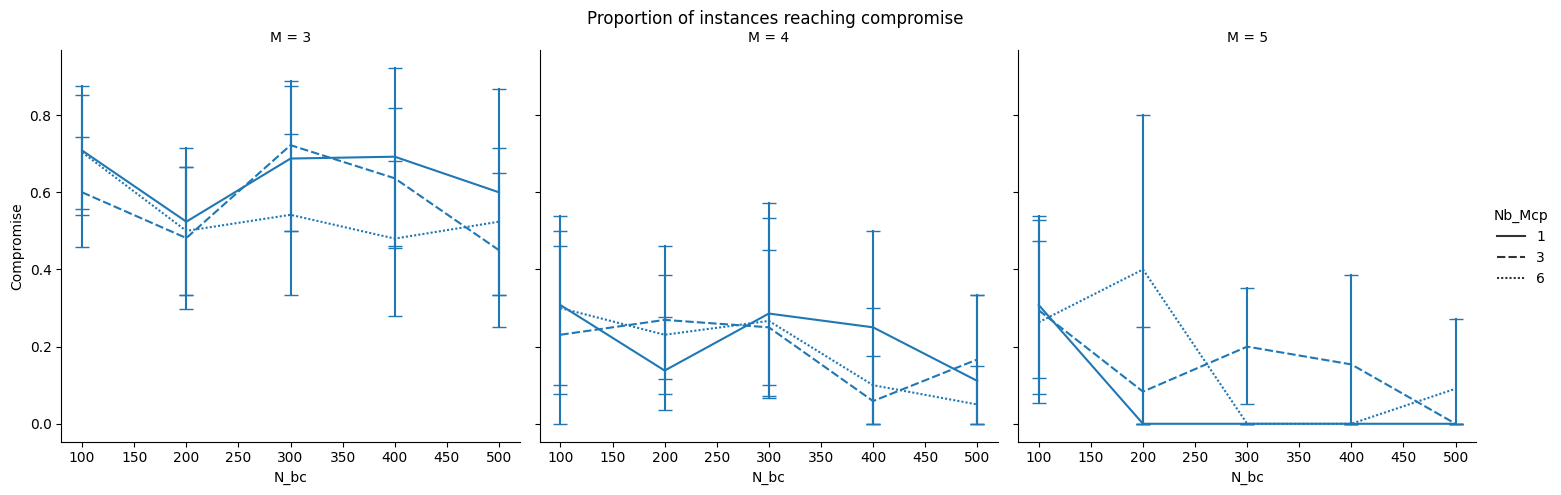

In [18]:
g = sns.relplot(
    # dff[(dff["Group"] == "Homo") & (~dff["Path"])],
    dff,
    x="N_bc",
    y="Compromise",
    col="M",
    # row="Ko",
    style="Nb_Mcp",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Proportion of instances reaching compromise")
g

tikzplotlib.save("mytikz.tex", standalone=True)

In [19]:
g = sns.relplot(
    dff[~dff["Path"] & (dff["Ko"] == 2)],
    x="N_bc",
    y="Compromise",
    # row="Group",
    col="Group_size",
    style="Group",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Proportion of instances reaching compromise")
g

tikzplotlib.save("mytikz.tex", standalone=True)

TypeError: 'NoneType' object is not iterable

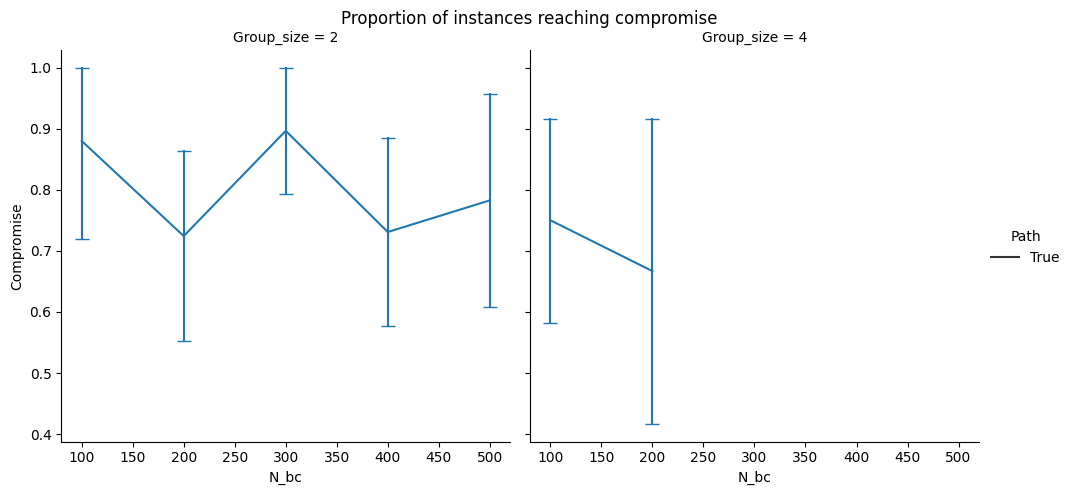

In [ ]:
g = sns.relplot(
    dff,#dff[(dff["Group"] == "Homo") & (dff["Ko"] == 2)],
    x="N_bc",
    y="Compromise",
    # row="Group",
    col="Group_size",
    style="Path",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Proportion of instances reaching compromise")
g

tikzplotlib.save("mytikz.tex", standalone=True)

## Sum of changes

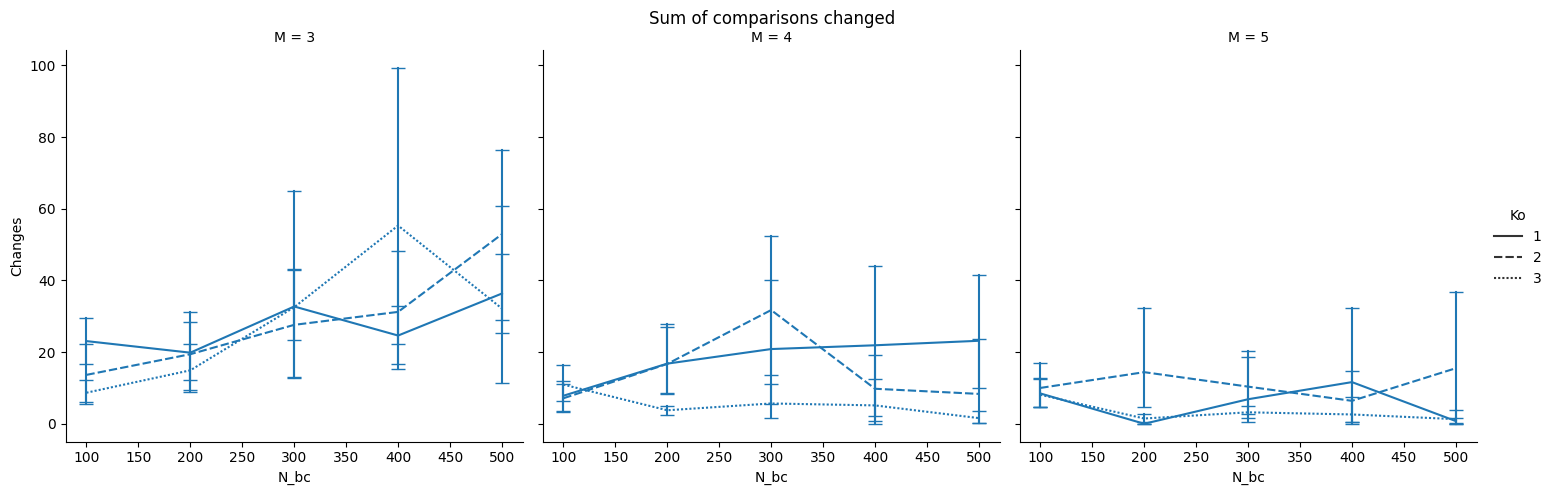

In [ ]:
g = sns.relplot(
    dff,
    x="N_bc",
    y="Changes",
    # row="M",
    col="M",
    style="Ko",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Sum of comparisons changed")
g

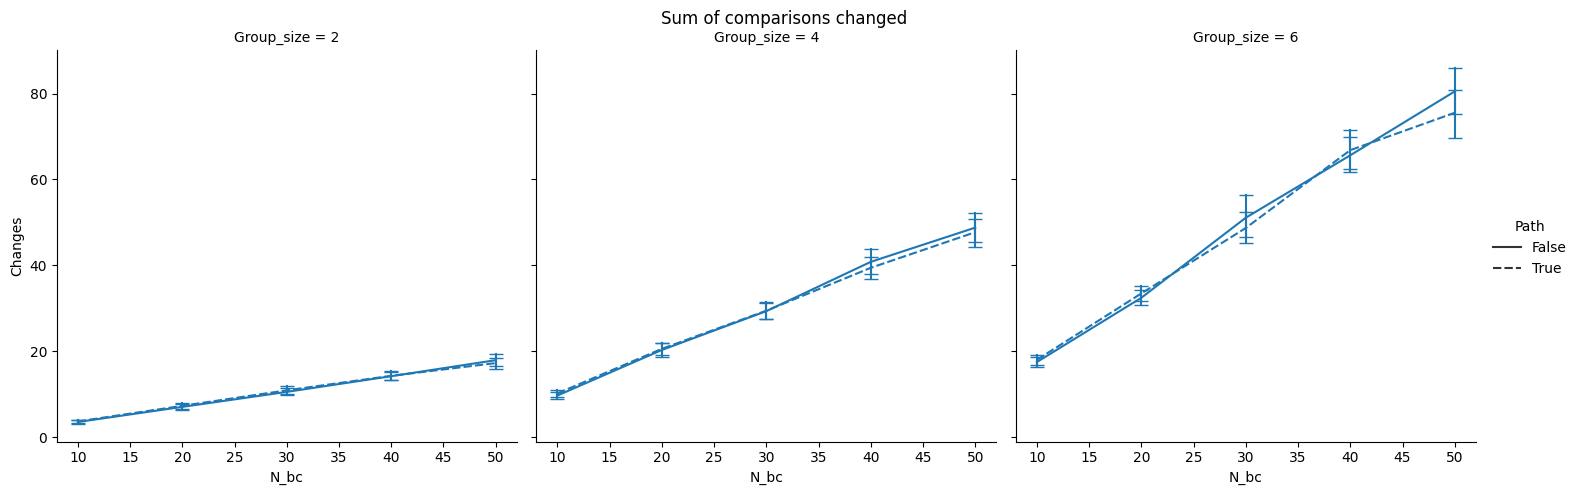

In [ ]:
g = sns.relplot(
    dff,
    x="N_bc",
    y="Changes",
    # row="Group_size",
    col="Group_size",
    style="Path",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Sum of comparisons changed")
g

## Mean of changes

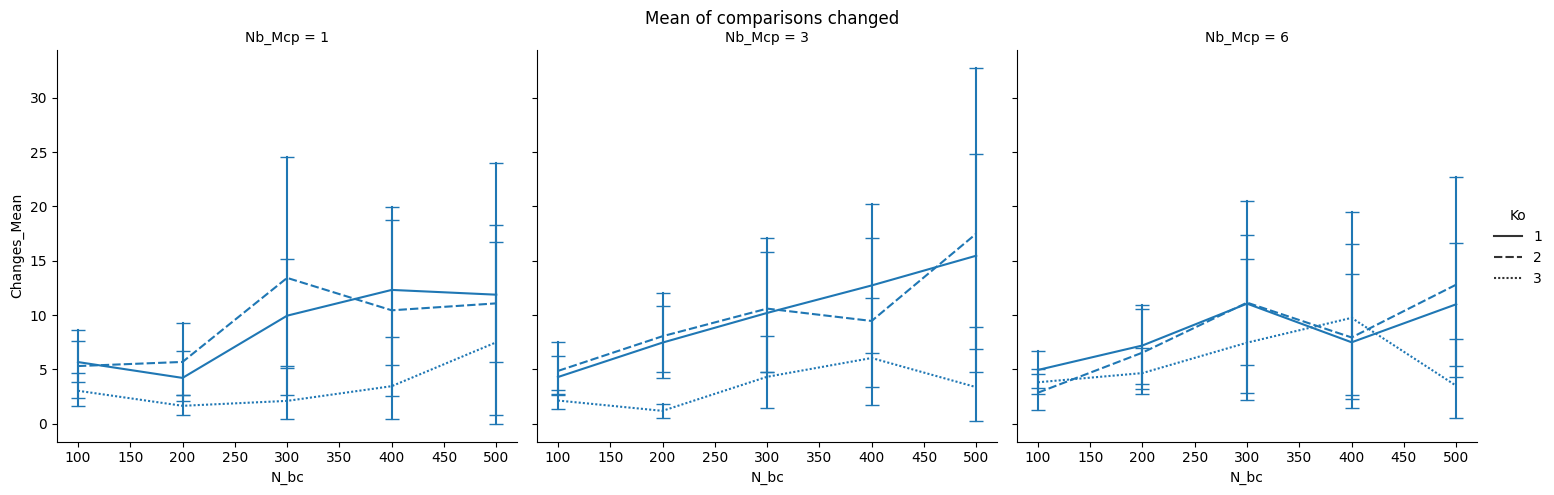

In [ ]:
g = sns.relplot(
    dff,
    x="N_bc",
    y="Changes_Mean",
    # row="M",
    col="Nb_Mcp",
    style="Ko",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Mean of comparisons changed")
g

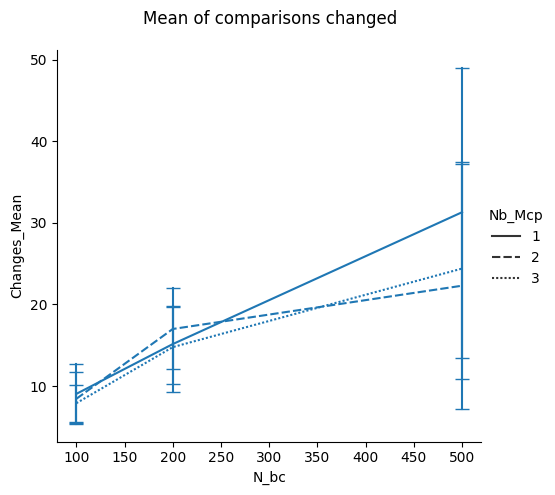

In [ ]:
g = sns.relplot(
    dff[dff["Compromise"]],
    x="N_bc",
    y="Changes_Mean",
    # row="Group_size",
    # col="M",
    style="Nb_Mcp",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Mean of comparisons changed")
g

## Proportion of changes

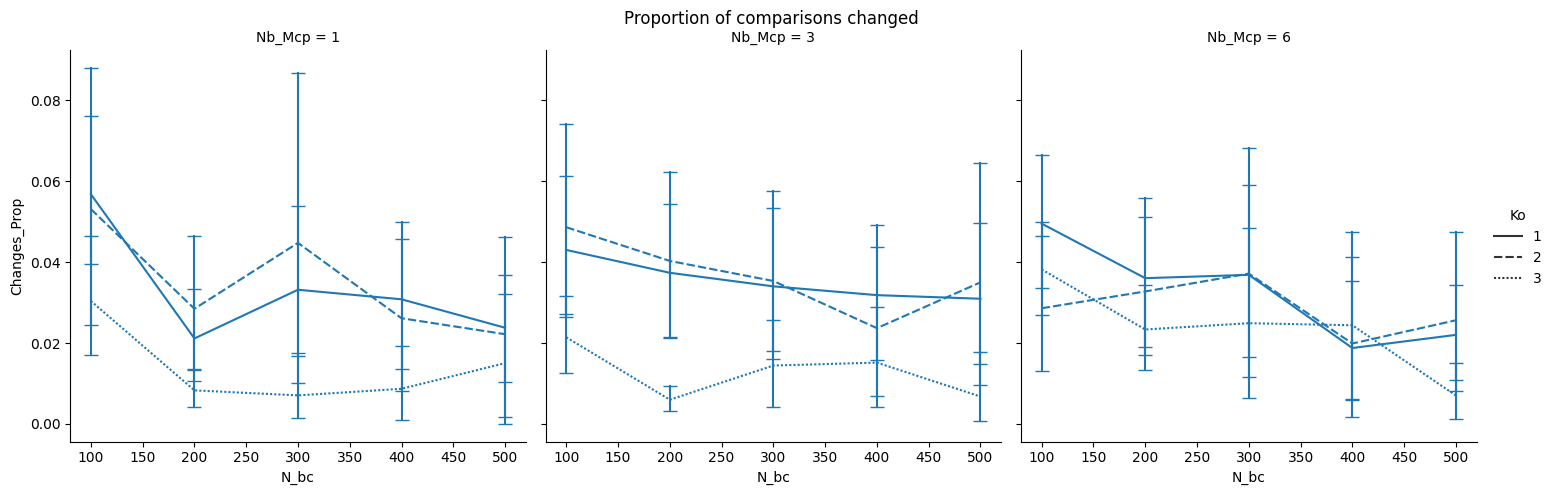

In [ ]:
g = sns.relplot(
    dff,
    x="N_bc",
    y="Changes_Prop",
    # row="M",
    col="Nb_Mcp",
    style="Ko",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Proportion of comparisons changed")
g

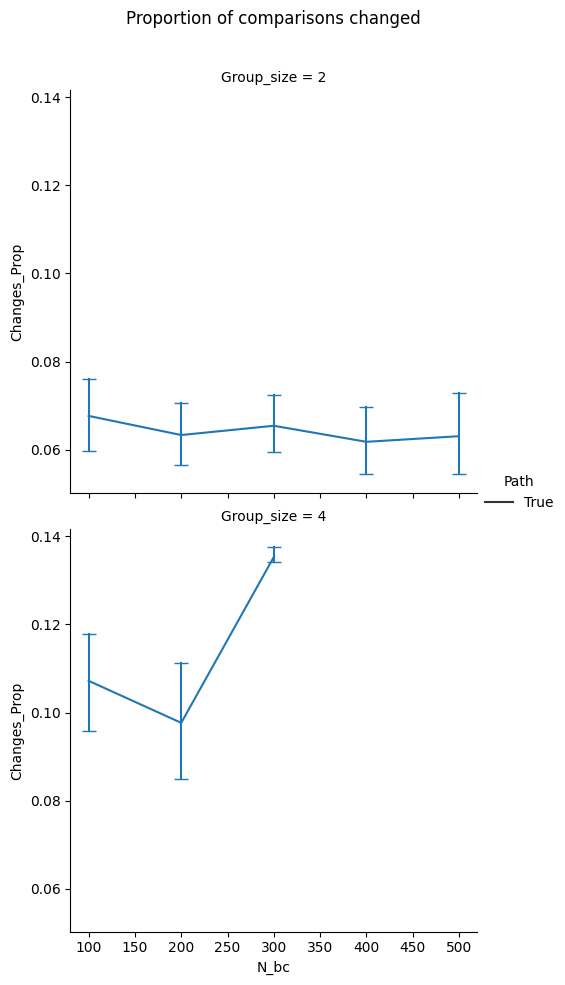

In [ ]:
g = sns.relplot(
    dff[dff["Compromise"]],
    x="N_bc",
    y="Changes_Prop",
    # row="Group_size",
    # col="M",
    style="Path",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Proportion of comparisons changed")
g

## MILP / SA objective value

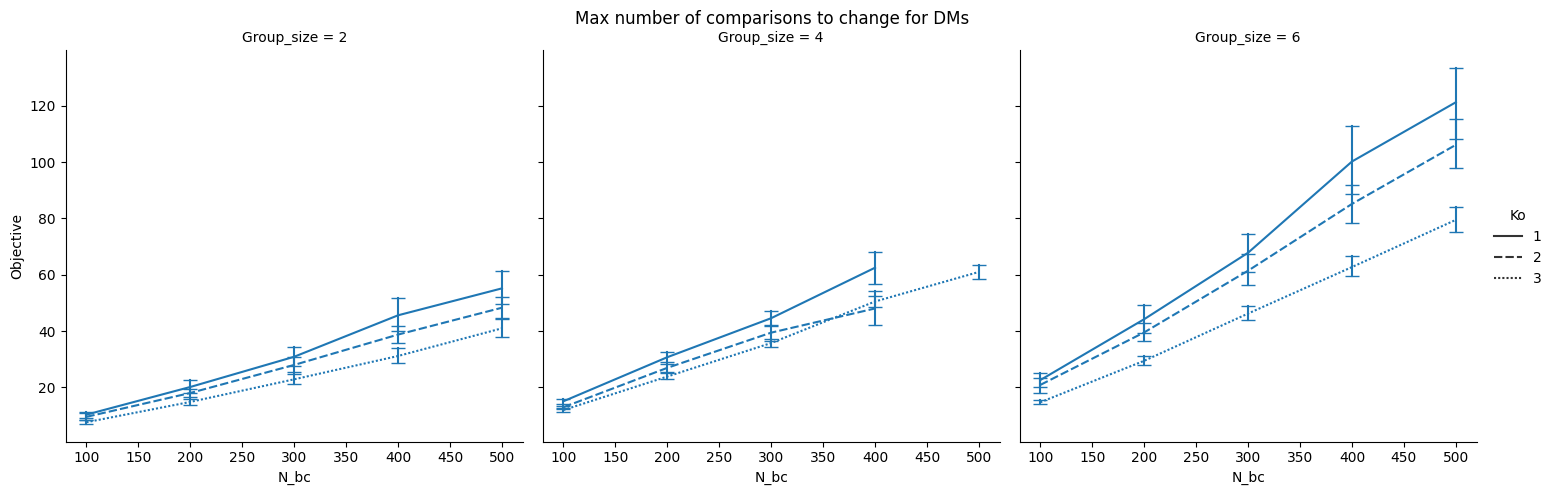

In [ ]:
g = sns.relplot(
    # df_collective_exp[(~df_collective_exp["Path"]) & (df_collective_exp["Group"] == "Homo")],
    df_collective_exp,
    x="N_bc",
    y="Objective",
    # row="M",
    col="Group_size",
    style="Ko",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Max number of comparisons to change for DMs")
g

tikzplotlib.save("mytikz.tex", standalone=True)

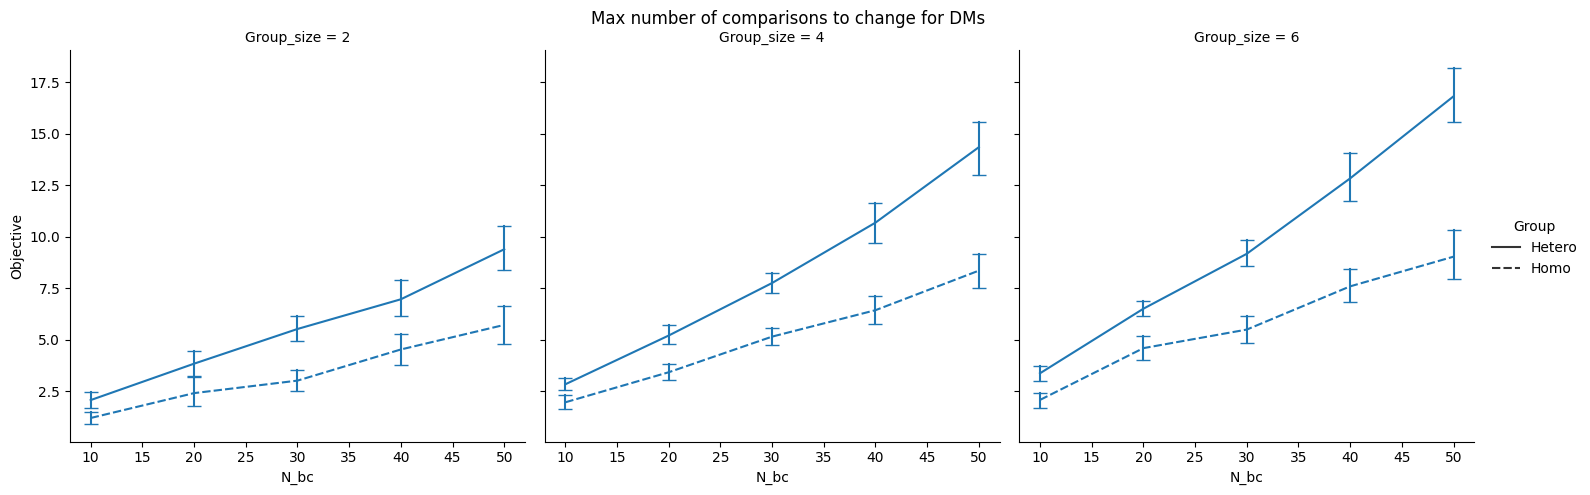

In [ ]:
g = sns.relplot(
    df_collective_exp[(~df_collective_exp["Path"]) & (df_collective_exp["Ko"] == 2)],
    x="N_bc",
    y="Objective",
    # row="Group",
    col="Group_size",
    style="Group",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Max number of comparisons to change for DMs")
g

tikzplotlib.save("mytikz.tex", standalone=True)

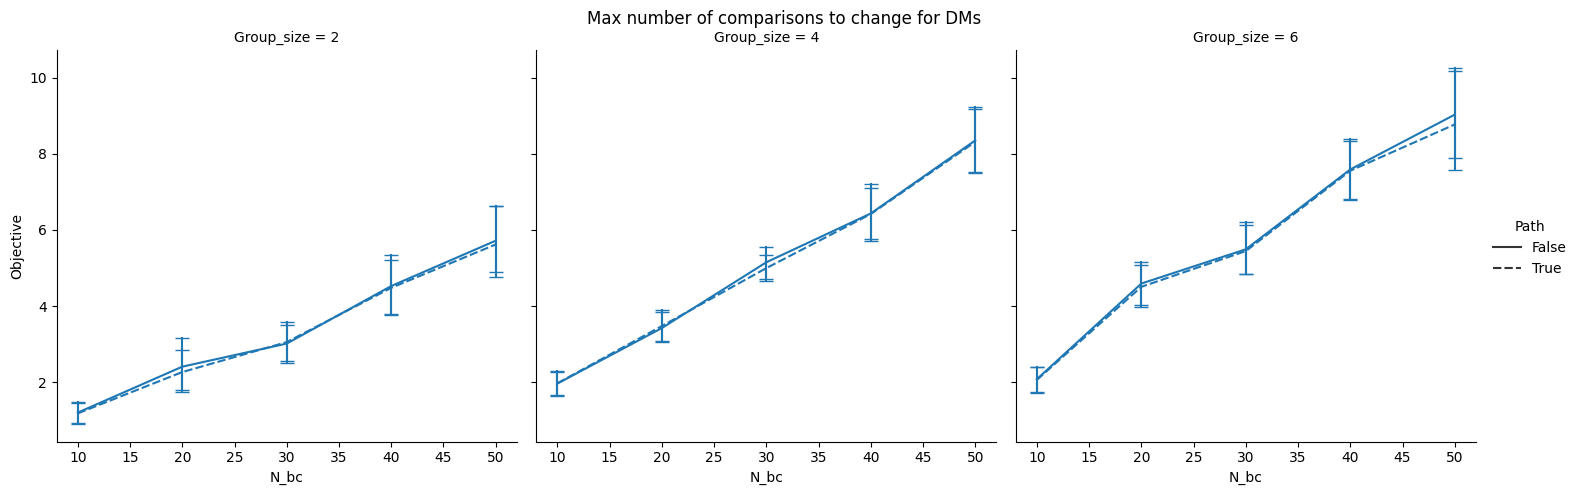

In [ ]:
g = sns.relplot(
    df_collective_exp[(df_collective_exp["Group"] == "Homo") & (df_collective_exp["Ko"] == 2)],
    x="N_bc",
    y="Objective",
    col="Group_size",
    # col="M",
    style="Path",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Max number of comparisons to change for DMs")
g

tikzplotlib.save("mytikz.tex", standalone=True)

## Proportion MILP / SA objective value

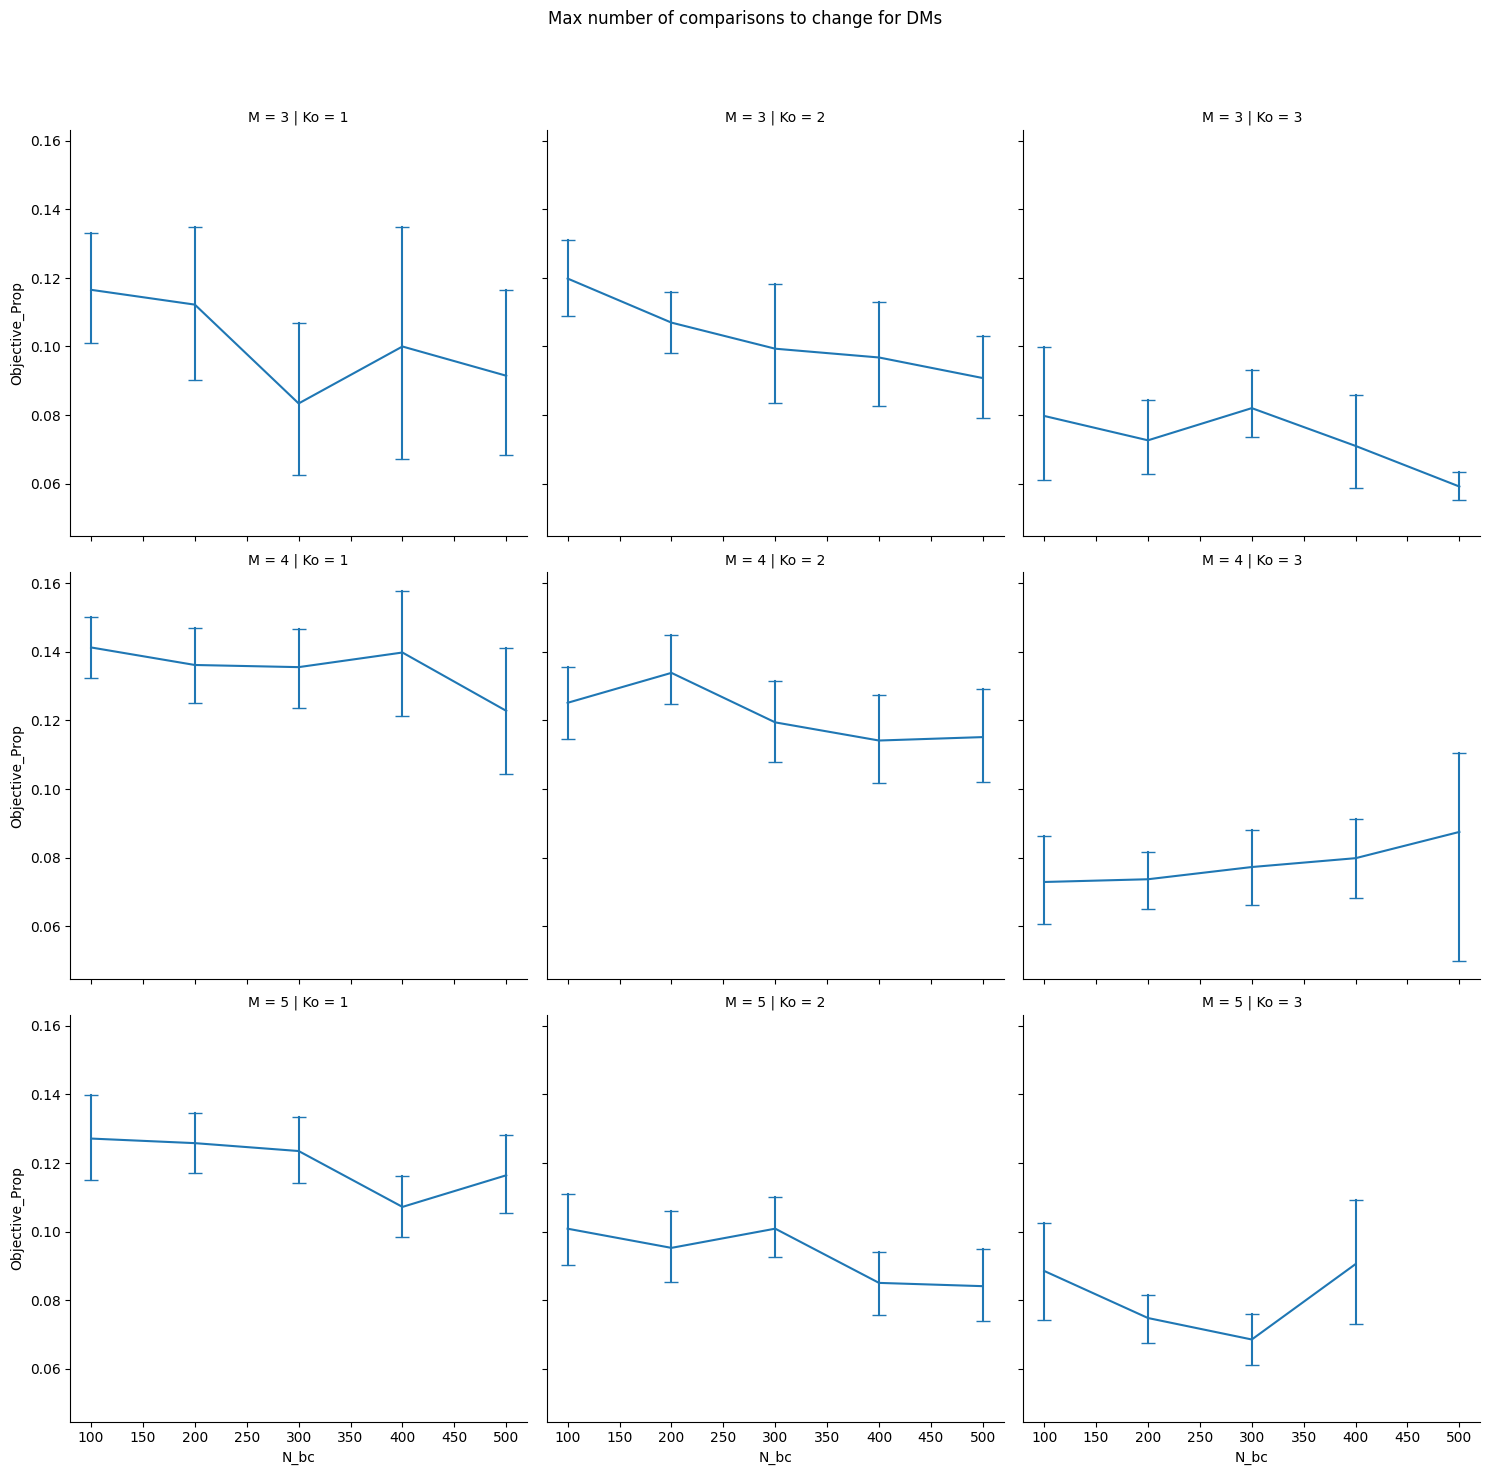

In [ ]:
g = sns.relplot(
    df_collective_exp,
    x="N_bc",
    y="Objective_Prop",
    row="M",
    col="Ko",
    # style="Nb_Mcp",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Max number of comparisons to change for DMs")
g

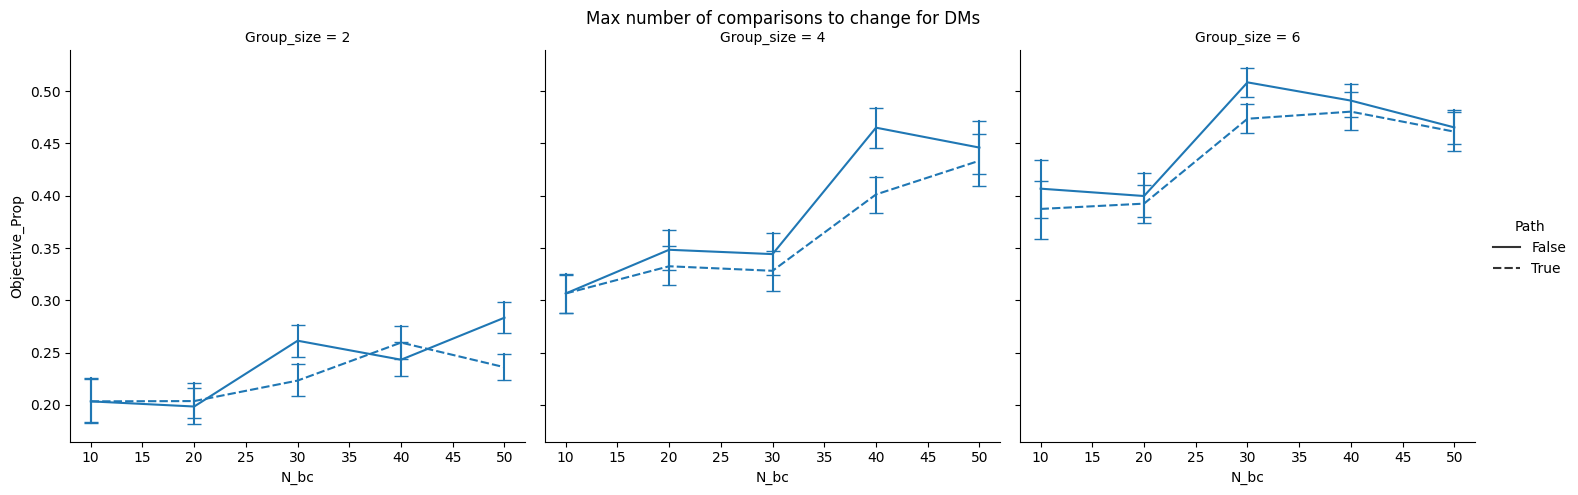

In [ ]:
g = sns.relplot(
    df_collective_exp,
    x="N_bc",
    y="Objective_Prop",
    # row="Group_size",
    col="Group_size",
    style="Path",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Max number of comparisons to change for DMs")
g

## MILP / SA optimal

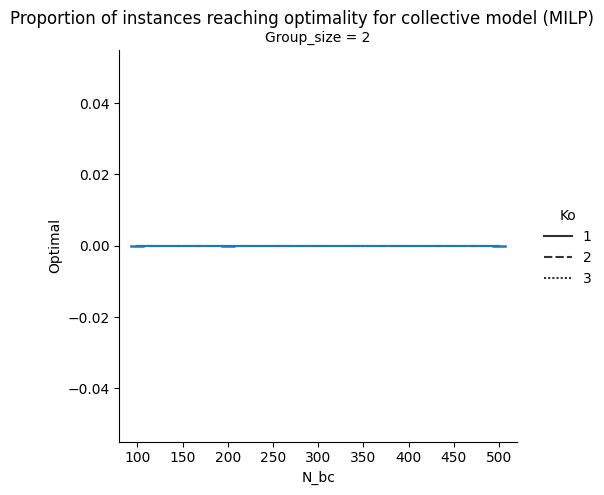

In [ ]:
g = sns.relplot(
    df_collective,
    x="N_bc",
    y=df_collective["Optimal"],
    col="Group_size",
    # row="Group_size",
    style="Ko",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Proportion of instances reaching optimality for collective model (MILP)")
g

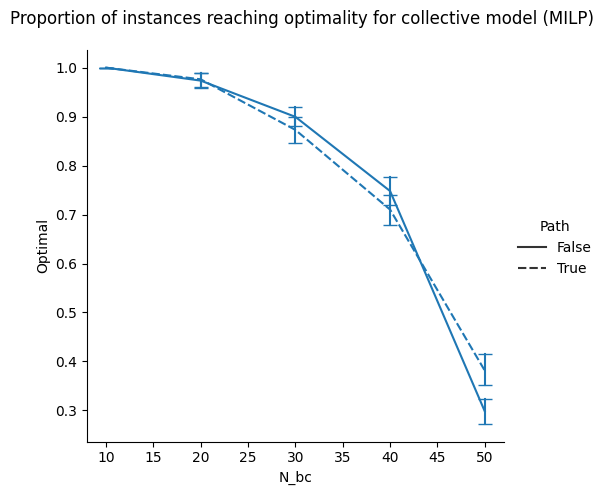

In [ ]:
g = sns.relplot(
    df_collective,
    x="N_bc",
    y=df_collective["Optimal"],
    # col="M",
    # row="Group_size",
    style="Path",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Proportion of instances reaching optimality for collective model (MILP)")
g

## Distance

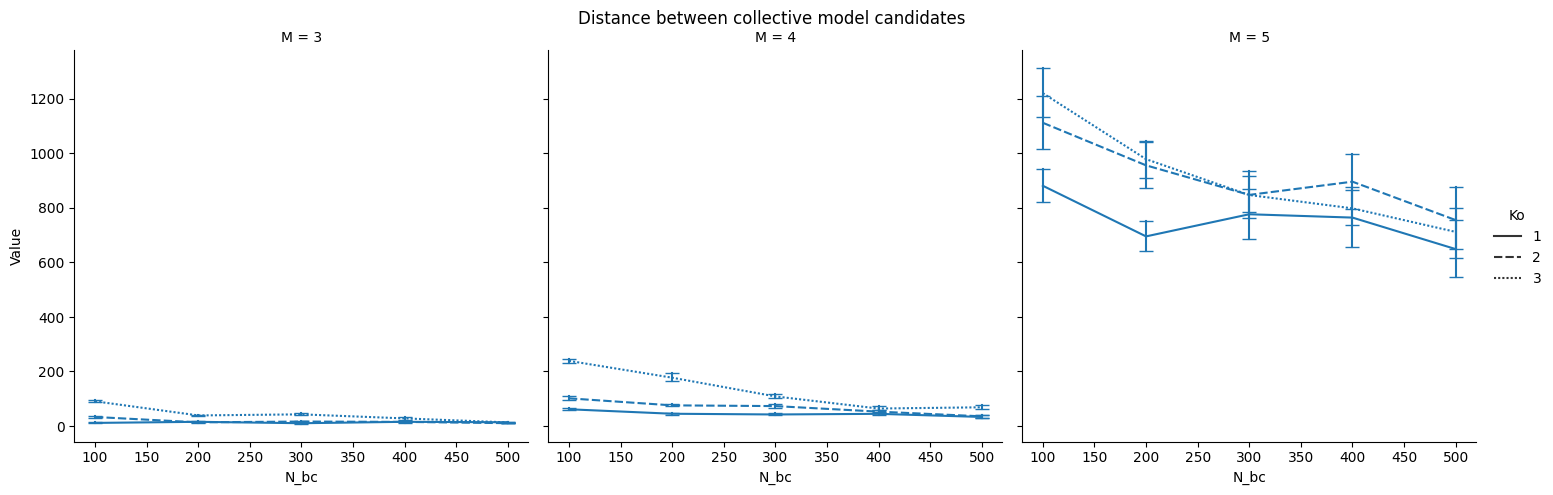

In [ ]:
g = sns.relplot(
    df_distance[df_distance["Time"] < 60],
    x="N_bc",
    y="Value",
    # row="Nb_Mcp",
    col="M",
    style="Ko",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Distance between collective model candidates")
g
tikzplotlib.save("mytikz.tex", standalone=True)

## Path optimal

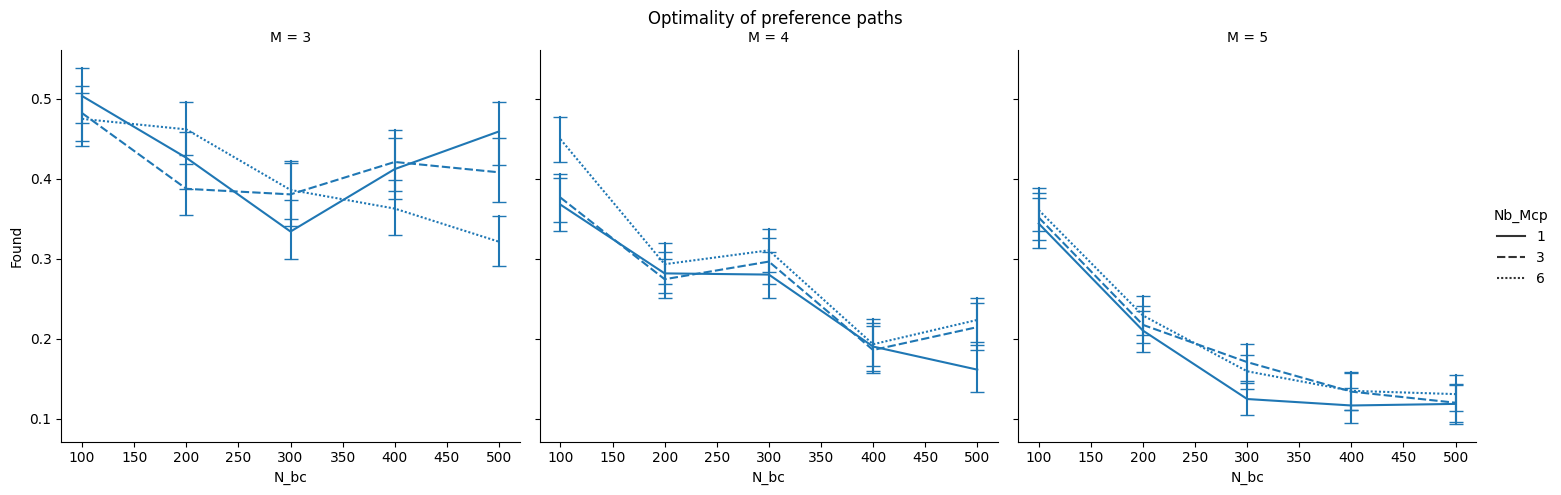

In [ ]:
g = sns.relplot(
    df_path[df_path["Length"] > 0],
    x="N_bc",
    y="Found",
    # row="M",
    col="M",
    style="Nb_Mcp",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Optimality of preference paths")
g

## Computing time

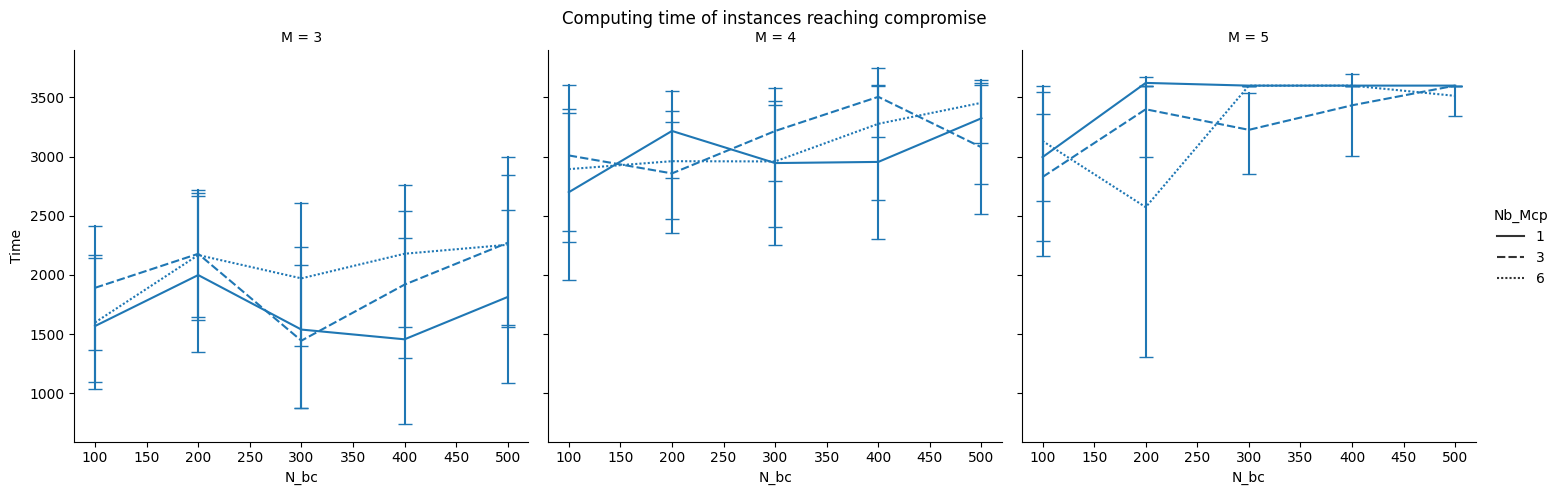

In [ ]:
g = sns.relplot(
    dff,
    x="N_bc",
    y="Time",
    # row="Ko",
    col="M",
    style="Nb_Mcp",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Computing time of instances reaching compromise")
g

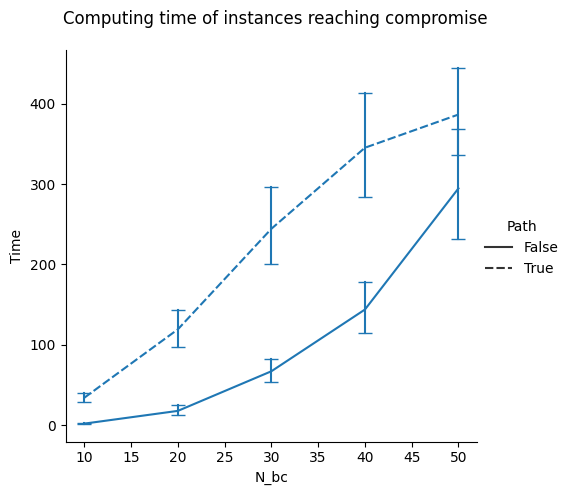

In [ ]:
g = sns.relplot(
    dff[dff["Compromise"]],
    x="N_bc",
    y="Time",
    # row="Group_size",
    # col="M",
    style="Path",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Computing time of instances reaching compromise")
g

## Computing time per it

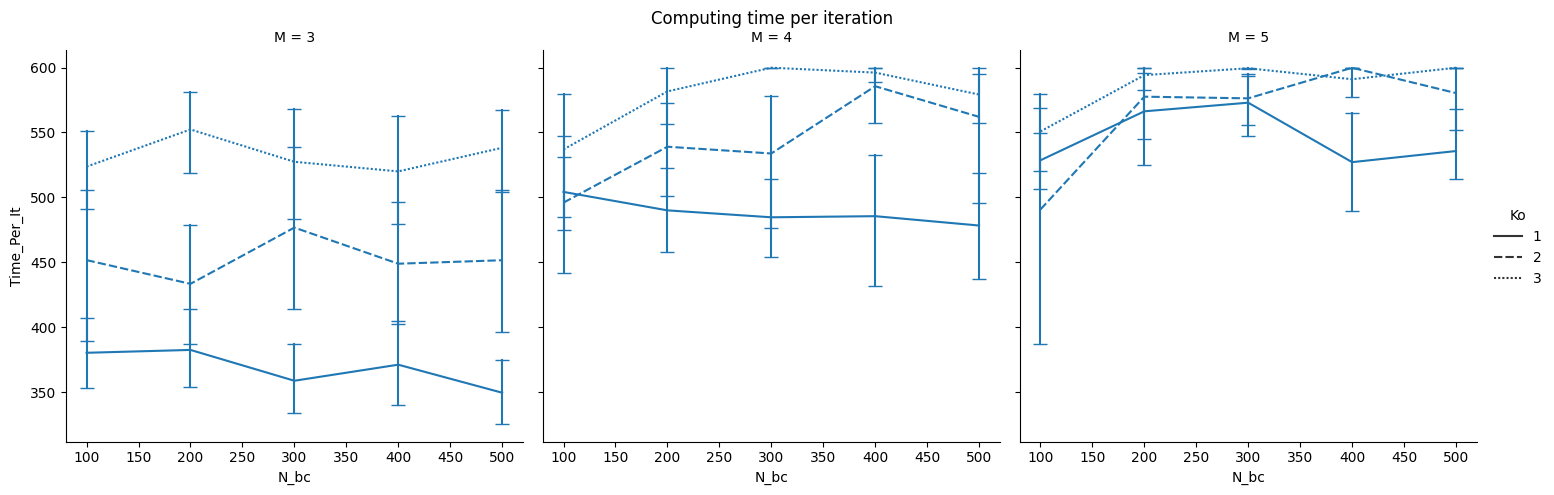

In [20]:
g = sns.relplot(
    dff,#[dff["Compromise"]],#[dff["Ko"] == 2],# & (~ dff["Path"]) & (dff["Group"] == "Homo")],
    x="N_bc",
    y="Time_Per_It",
    # row="M",
    col="M",
    style="Ko",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Computing time per iteration")
g

tikzplotlib.save("mytikz.tex", standalone=True)

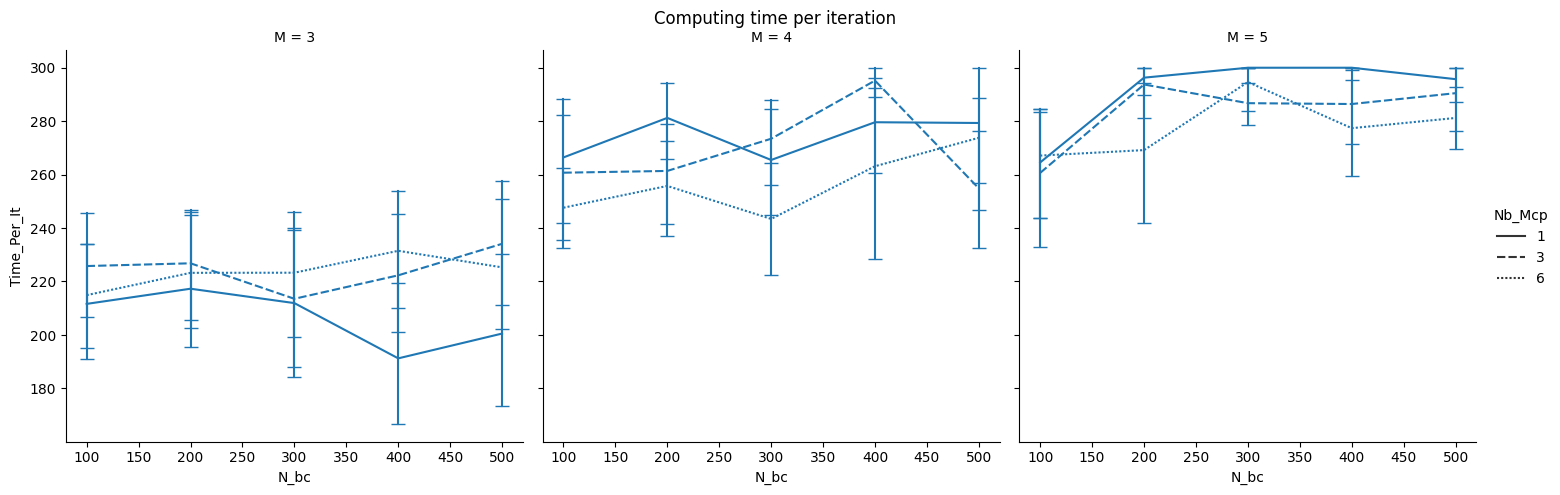

In [25]:
g = sns.relplot(
    dff,#[dff["Compromise"]],#[dff["Ko"] == 2],# & (~ dff["Path"]) & (dff["Group"] == "Homo")],
    x="N_bc",
    y="Time_Per_It",
    # row="M",
    col="M",
    style="Nb_Mcp",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Computing time per iteration")
g

tikzplotlib.save("mytikz.tex", standalone=True)

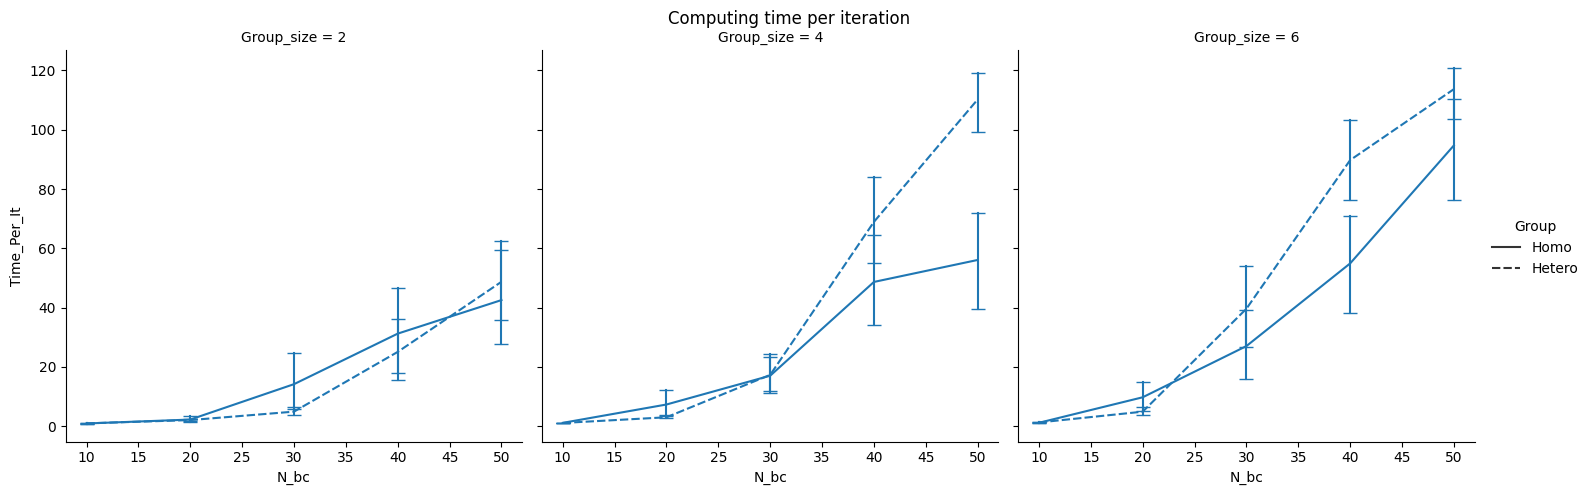

In [ ]:
g = sns.relplot(
    dff[dff["Compromise"] & (~ dff["Path"]) & (dff["Ko"] == 2)],
    x="N_bc",
    y="Time_Per_It",
    # row="Group",
    col="Group_size",
    style="Group",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Computing time per iteration")
g

tikzplotlib.save("mytikz.tex", standalone=True)

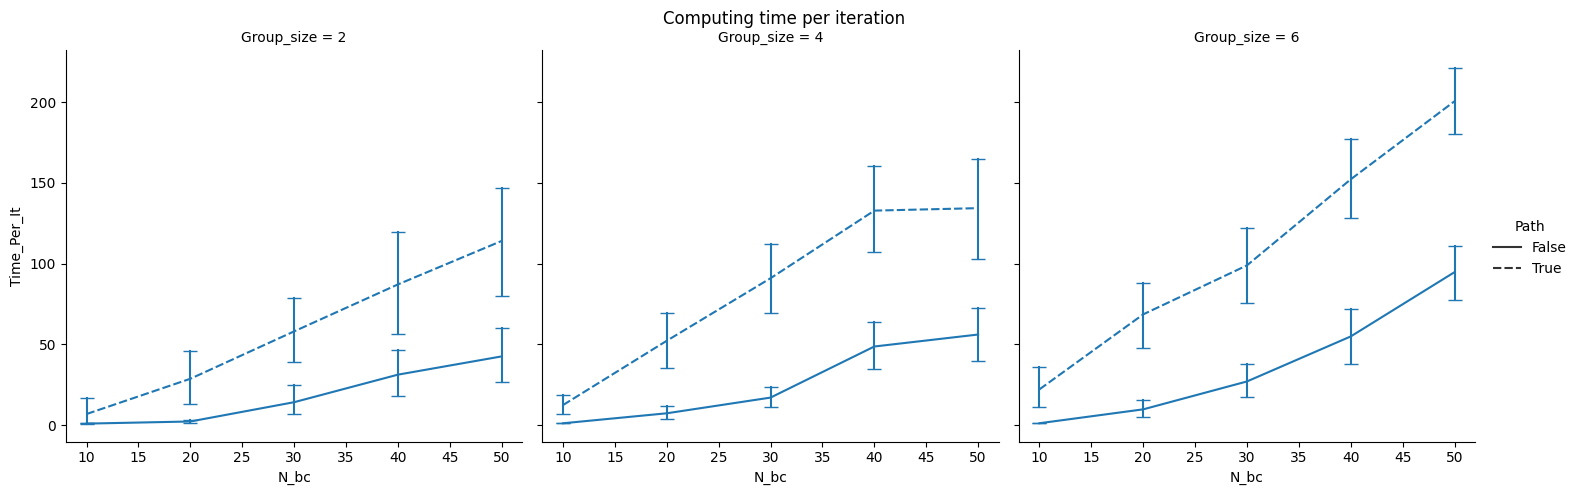

In [ ]:
g = sns.relplot(
    dff[dff["Compromise"] & (dff["Group"] == "Homo") & (dff["Ko"] == 2)],
    x="N_bc",
    y="Time_Per_It",
    # row="Group_size",
    col="Group_size",
    style="Path",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Computing time per iteration")
g

tikzplotlib.save("mytikz.tex", standalone=True)

## MILP computing time

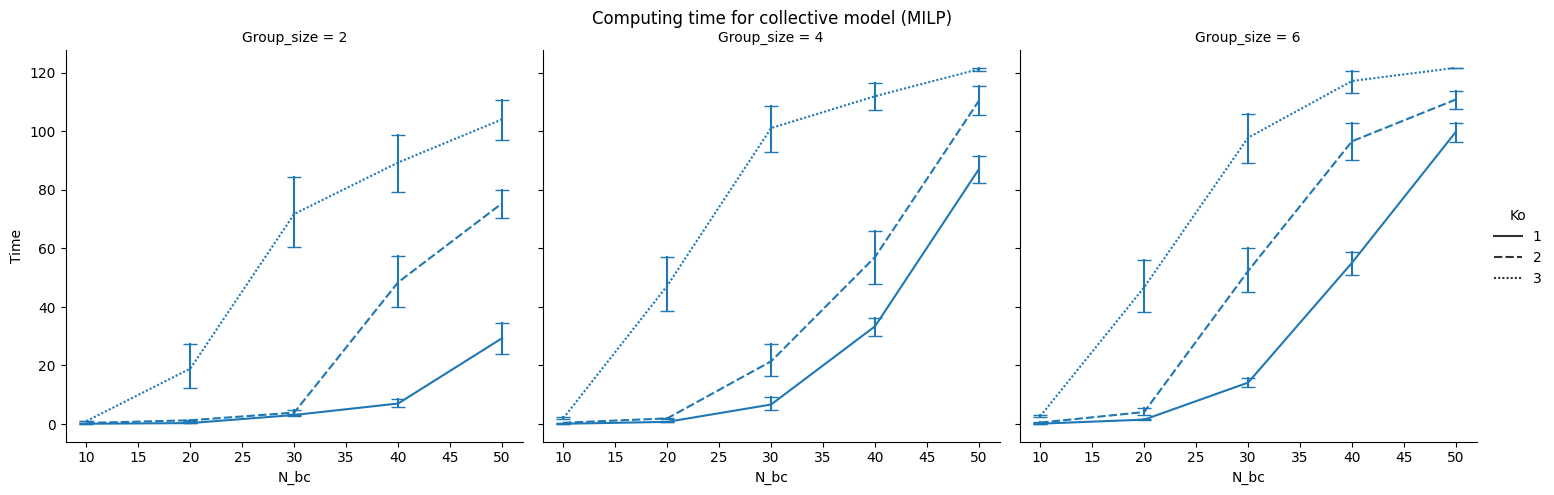

In [ ]:
g = sns.relplot(
    df_collective,
    x="N_bc",
    y="Time",
    # row="Group_size",
    col="Group_size",
    style="Ko",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Computing time for collective model (MILP)")
g

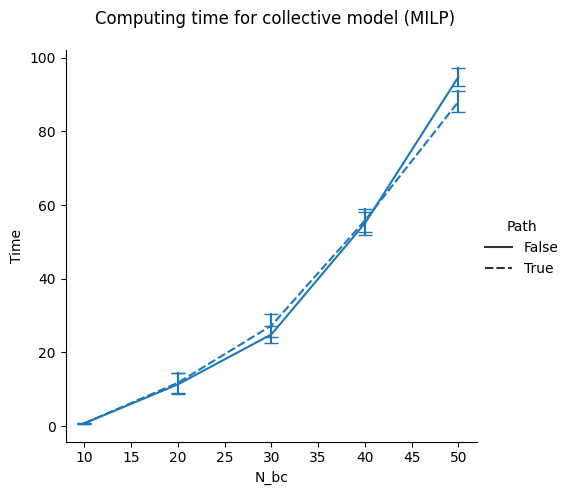

In [ ]:
g = sns.relplot(
    df_collective,
    x="N_bc",
    y="Time",
    # row="Group_size",
    # col="M",
    style="Path",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Computing time for collective model (MILP)")
g

## Preference path computing time

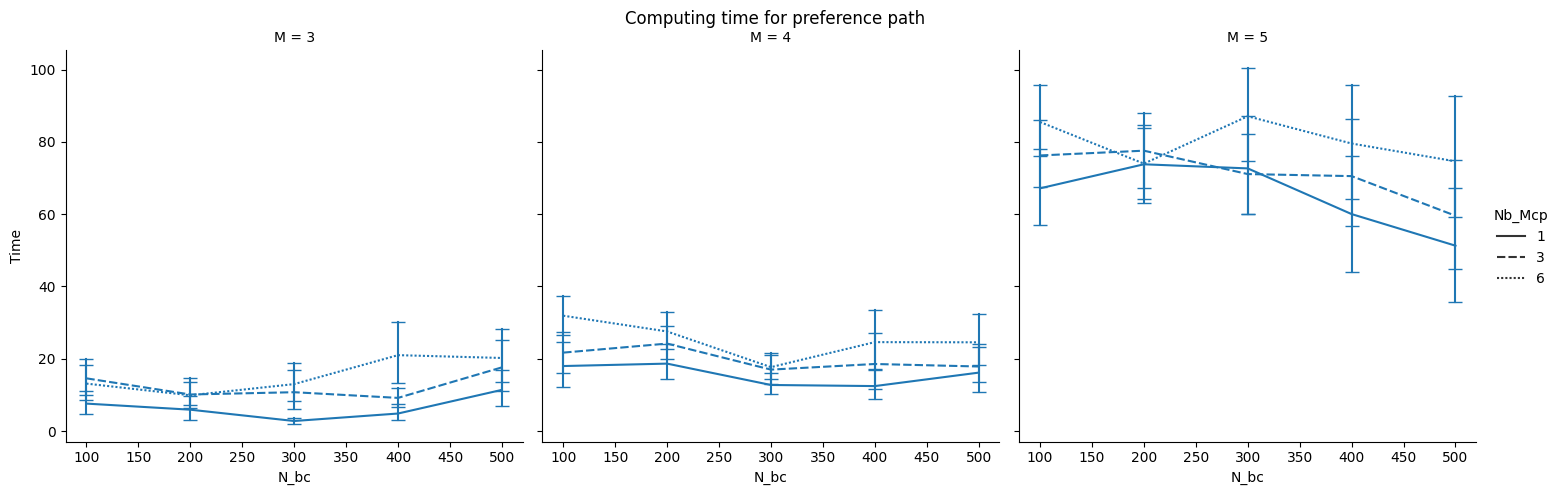

In [ ]:
# (df_path["Found"])
g = sns.relplot(
    df_path[(df_path["Found"])],
    x="N_bc",
    y="Time",
    col="M",
    # row="M",
    style="Nb_Mcp",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Computing time for preference path")
g

## Iterations

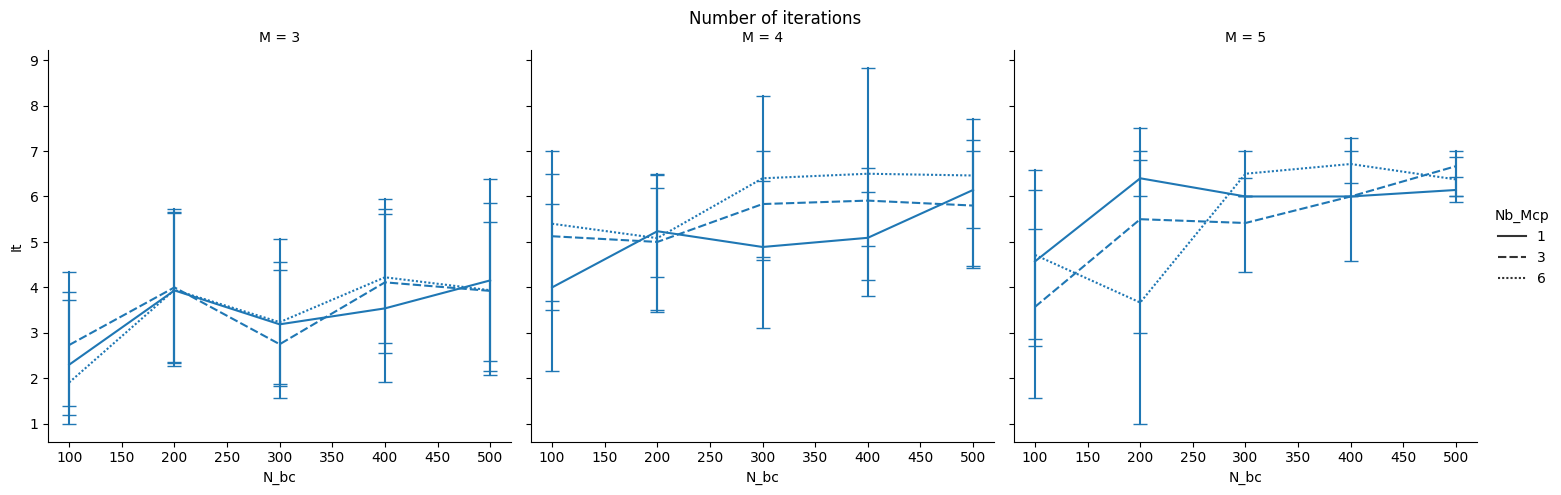

In [ ]:
g = sns.relplot(
    # dff[dff["Compromise"] & (~dff["Path"]) & (dff["Group"] == "Homo")],
    dff,
    x="N_bc",
    y="It",
    # row="M",
    col="M",
    style="Nb_Mcp",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Number of iterations")
g

tikzplotlib.save("mytikz.tex", standalone=True)

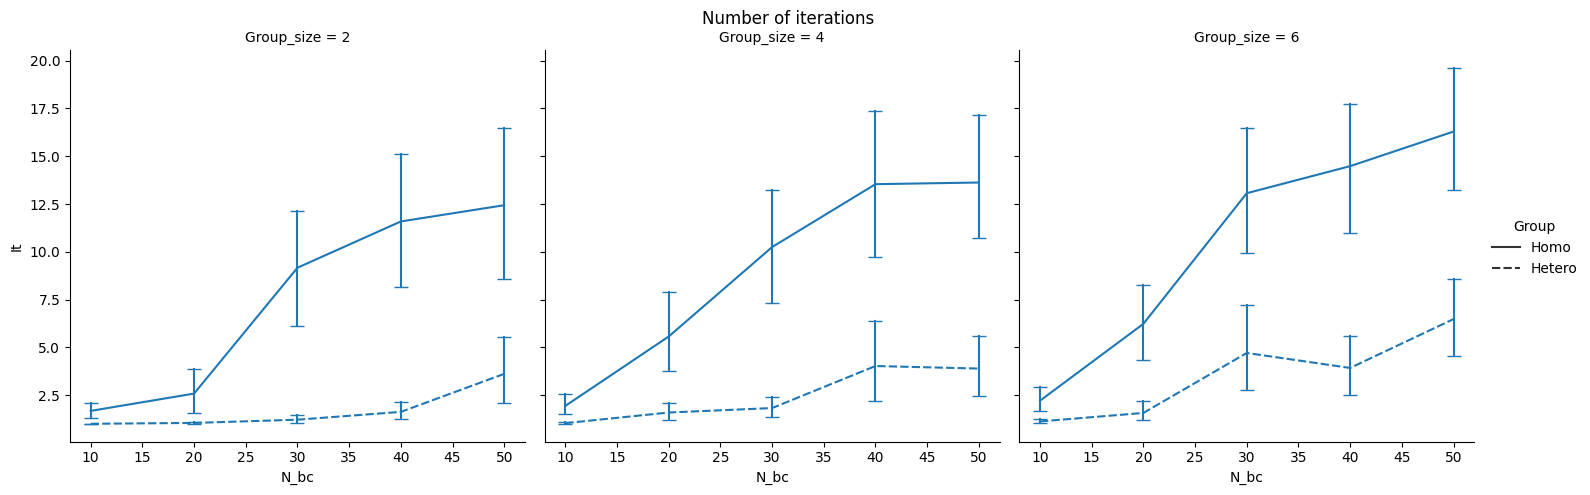

In [ ]:
g = sns.relplot(
    dff[(~dff["Path"])],
    x="N_bc",
    y="It",
    col="Group_size",
    # row="Group",
    style="Group",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Number of iterations")
g

tikzplotlib.save("mytikz.tex", standalone=True)

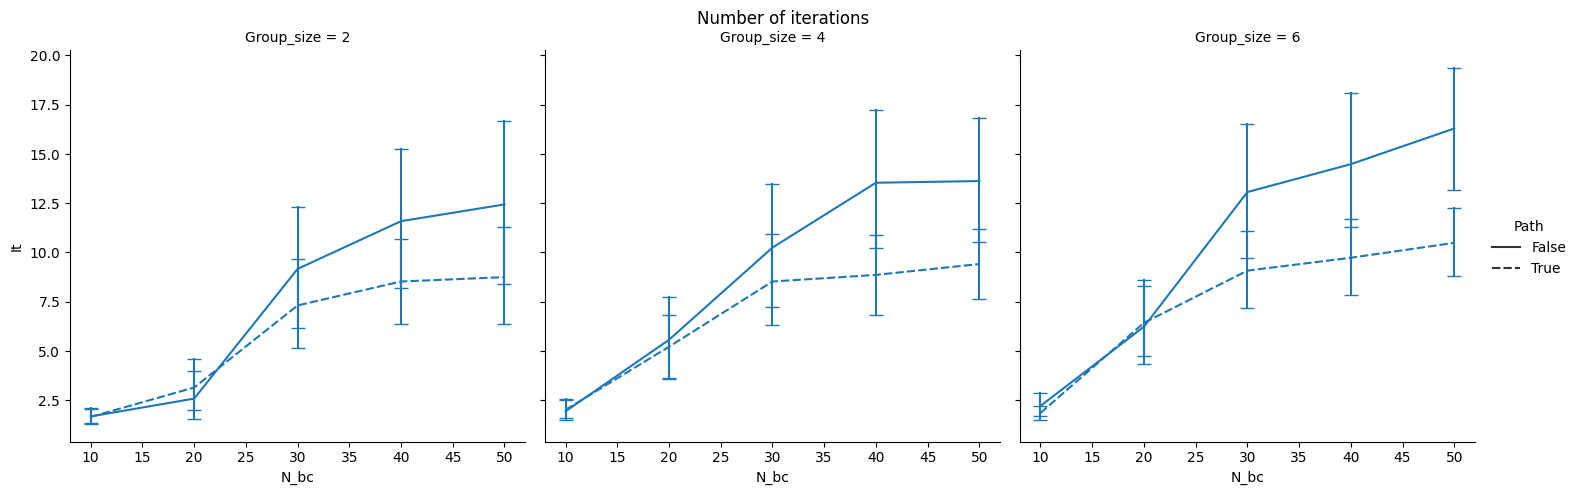

In [ ]:
g = sns.relplot(
    dff[(dff["Group"] == "Homo")],
    x="N_bc",
    y="It",
    col="Group_size",
    # row="Group",
    style="Path",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Number of iterations")
g

tikzplotlib.save("mytikz.tex", standalone=True)

## Length of model preference paths

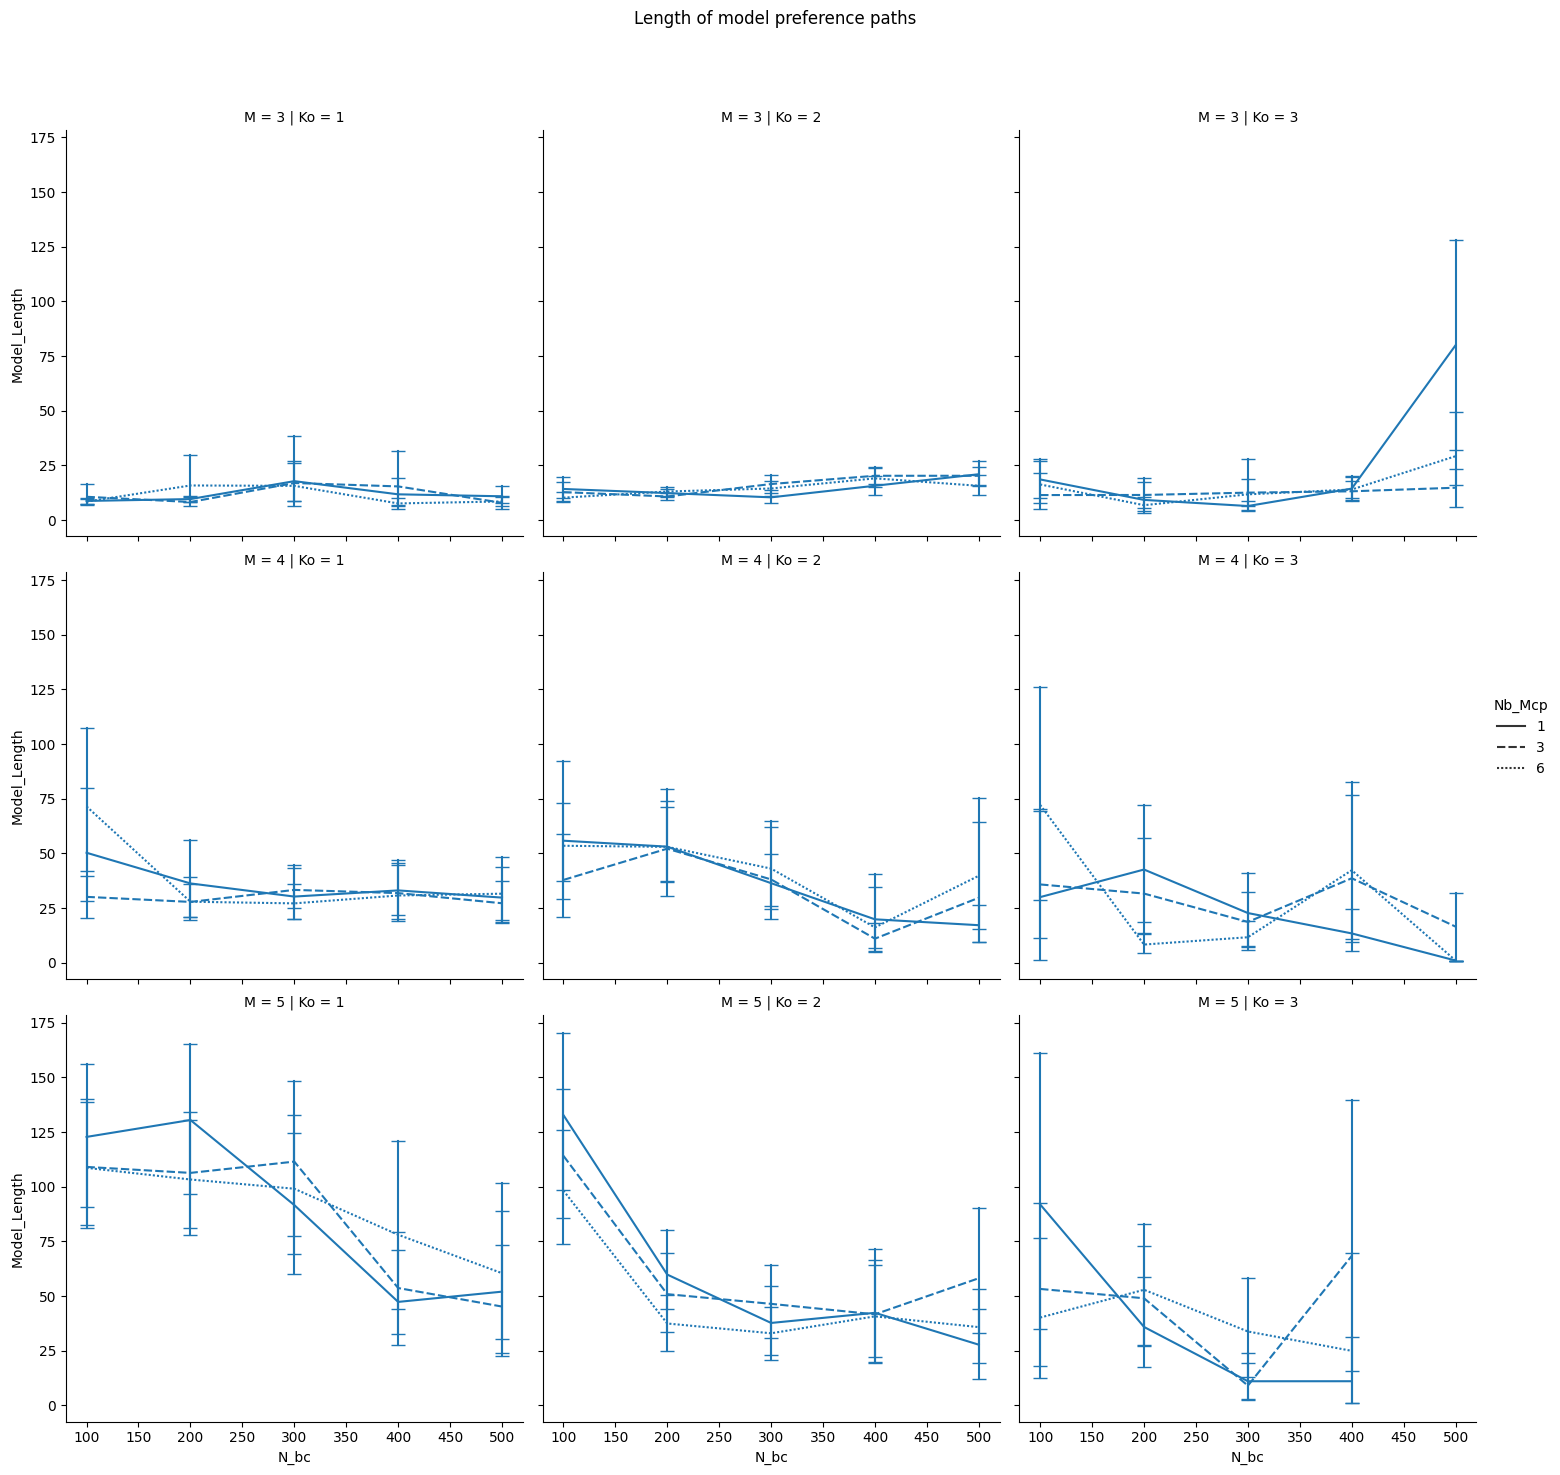

In [ ]:
g = sns.relplot(
    df_path[df_path["Length"] > 0],
    x="N_bc",
    y="Model_Length",
    row="M",
    col="Ko",
    style="Nb_Mcp",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Length of model preference paths")
g

## Length of preference paths

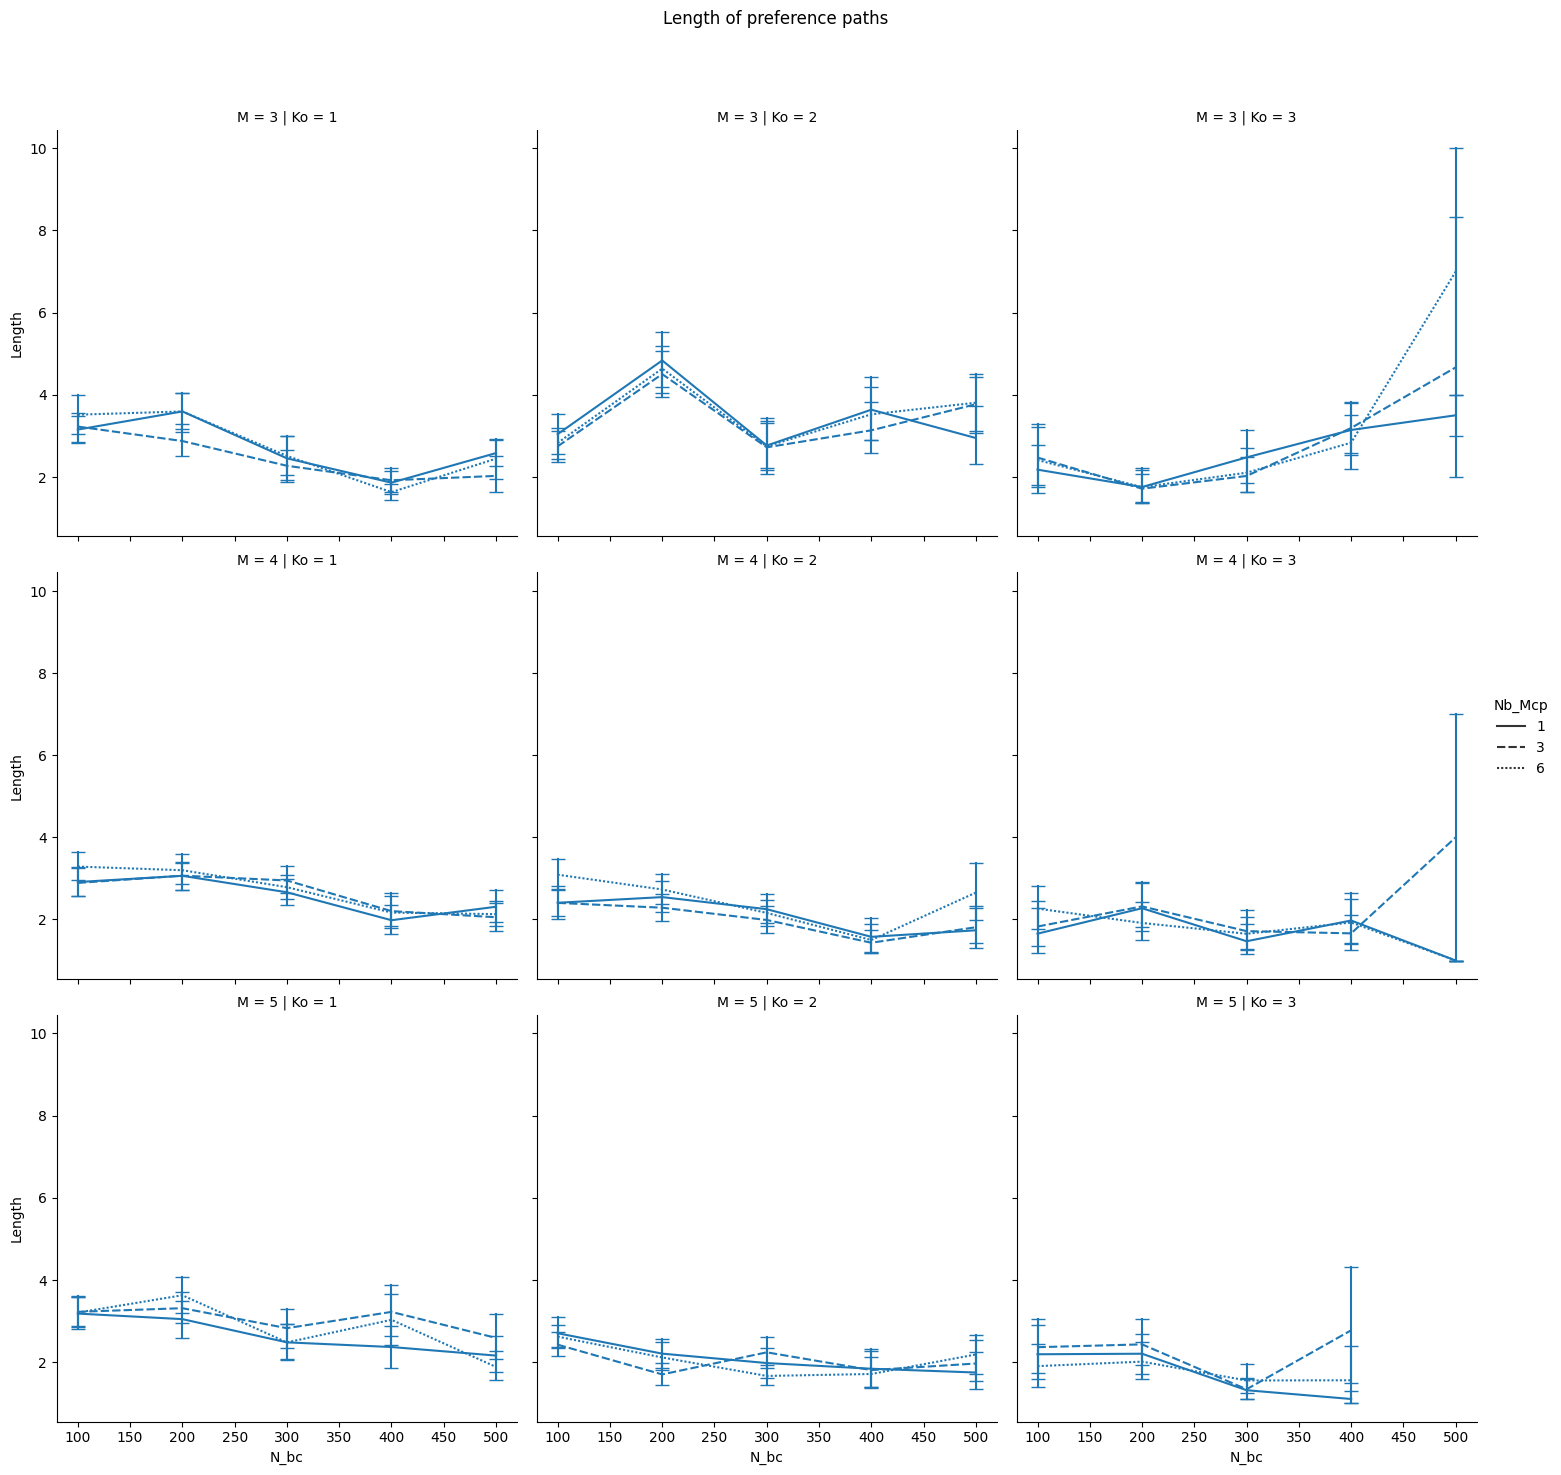

In [ ]:
g = sns.relplot(
    df_path[df_path["Length"] > 0],
    x="N_bc",
    y="Length",
    row="M",
    col="Ko",
    style="Nb_Mcp",
    kind="line",
    errorbar=("ci", 95),
    err_style="bars",
    err_kws={"capsize": 5},
)
g.figure.subplots_adjust(top=0.9)
g.figure.suptitle("Length of preference paths")
g